# Knowledge Graph Construction with Claude

You have a pile of unstructured documents and need to answer questions that span them — "who works with people who worked on project X", "which vendors are connected to this incident". No single document contains the answer. RAG retrieval won't chain the facts for you. You need a knowledge graph: **entities** as nodes, **typed relations** as edges, so that multi-hop reasoning becomes graph traversal.

Building one used to mean training a named-entity recognizer on your domain, training a relation classifier, writing entity-resolution heuristics, and maintaining all three as your data shifted. With Claude, each of those stages becomes a prompt.

## What you'll learn

By the end of this guide you will be able to:

- Use **structured outputs** to extract typed entities and subject–predicate–object triples from arbitrary text with no training data
- Apply **Claude-driven entity resolution** to collapse surface-form variants into canonical nodes, replacing brittle string-similarity heuristics
- Assemble and query an in-memory graph, and run **multi-hop questions** by serializing subgraphs back to Claude
- Measure extraction quality with **precision/recall against a gold set** and reason about the cost/quality tradeoff between Haiku and Sonnet

Everything runs in memory with no database. The techniques transfer directly to Neo4j, Neptune, or a Postgres adjacency table when you need to scale.

## Prerequisites
- Python 3.11+
- Anthropic API key ([get one here](https://console.anthropic.com))
- Basic familiarity with graphs (nodes, edges, traversal)

## Setup

In [1]:
%%capture
%pip install anthropic requests networkx matplotlib python-dotenv pydantic

In [2]:
import json
from collections import defaultdict
from pathlib import Path
from typing import Literal
from urllib.parse import quote

import anthropic
import matplotlib.pyplot as plt
import networkx as nx
import requests
from dotenv import load_dotenv
from pydantic import BaseModel

load_dotenv()
client = anthropic.Anthropic()

EXTRACTION_MODEL = "claude-haiku-5-5"
SYNTHESIS_MODEL = "claude-sonnet-5-5"

We use two models. Haiku handles the high-volume, schema-constrained extraction work where speed and cost matter more than nuance. Sonnet handles entity resolution and summarization, where the model needs to weigh conflicting evidence across documents.

## Building a corpus

We need a handful of documents that talk about overlapping entities, so that entity resolution has real work to do. The Apollo program is a good test bed: six short Wikipedia summaries that all mention NASA, the Moon, several astronauts, and a launch vehicle — but each article names them slightly differently.

We fetch summaries from the Wikipedia REST API rather than full articles to keep token costs low. For a production pipeline you would chunk full documents; the extraction logic is identical.

In [3]:
ARTICLE_TITLES = [
    "Apollo program",
    "Apollo 11",
    "Neil Armstrong",
    "Saturn V",
    "Buzz Aldrin",
    "Kennedy Space Center",
]

WIKI_API = "https://en.wikipedia.org/api/rest_v1/page/summary/"
HEADERS = {"User-Agent": "claude-cookbooks/1.0 (https://github.com/anthropics/claude-cookbooks)"}


def fetch_summary(title: str) -> str:
    slug = quote(title.replace(" ", "_"), safe="")
    r = requests.get(WIKI_API + slug, headers=HEADERS, timeout=10)
    r.raise_for_status()
    return r.json()["extract"]


documents = []
for i, title in enumerate(ARTICLE_TITLES):
    try:
        documents.append({"id": i, "title": title, "text": fetch_summary(title)})
    except requests.RequestException as e:
        print(f"Skipping {title}: {e}")

if not documents:
    raise RuntimeError("No documents loaded — check network and Wikipedia API availability")
print(f"Loaded {len(documents)} documents\n")
print(f"Sample — {documents[0]['title']}:\n{documents[0]['text'][:300]}...")

Loaded 6 documents

Sample — Apollo program:
The Apollo program, also known as Project Apollo, was the United States human spaceflight program led by NASA, which landed the first humans on the Moon in 1969. The Apollo program was conceived in 1960 in the Dwight D. Eisenhower presidency during Project Mercury and executed after Project Gemini. ...


## Entity and relation extraction

Classical NER tags spans of text with labels (PERSON, ORG, LOC). Classical relation extraction then classifies pairs of spans into relation types. Both traditionally require labeled training data per domain.

We collapse both stages into a single Claude call per document. The key is **structured outputs**: we define the output shape as a Pydantic model and pass it to `client.messages.parse()`. Claude's response is guaranteed to validate against that schema and comes back as a typed Python object — no regex parsing, no JSON decode errors, no defensive `isinstance` checks.

In [4]:
EntityType = Literal["PERSON", "ORGANIZATION", "LOCATION", "EVENT", "ARTIFACT"]
ENTITY_TYPES = ["PERSON", "ORGANIZATION", "LOCATION", "EVENT", "ARTIFACT"]


class Entity(BaseModel):
    name: str
    type: EntityType
    description: str


class Relation(BaseModel):
    source: str
    predicate: str
    target: str


class ExtractedGraph(BaseModel):
    entities: list[Entity]
    relations: list[Relation]


EXTRACTION_PROMPT = """Extract a knowledge graph from the document below.

<document>
{text}
</document>

Guidelines:
- Extract only entities that are central to what this document is about — skip incidental mentions.
- For each entity, write a one-sentence description grounded in this document. These descriptions are used later to disambiguate entities with similar names.
- Predicates should be short verb phrases ("commanded", "launched from", "part of").
- Every relation must connect two entities you extracted."""


def extract(text: str) -> ExtractedGraph:
    response = client.messages.parse(
        model=EXTRACTION_MODEL,
        max_tokens=4096,
        messages=[{"role": "user", "content": EXTRACTION_PROMPT.format(text=text)}],
        output_format=ExtractedGraph,
    )
    return response.parsed_output

In [5]:
raw_entities = []
raw_relations = []

for doc in documents:
    try:
        result = extract(doc["text"])
    except anthropic.APIError as e:
        print(f"Skipping {doc['title']}: {e}")
        continue
    for ent in result.entities:
        raw_entities.append({**ent.model_dump(), "source_doc": doc["title"]})
    for rel in result.relations:
        raw_relations.append({**rel.model_dump(), "source_doc": doc["title"]})
    print(
        f"{doc['title']:<25} {len(result.entities):>3} entities  {len(result.relations):>3} relations"
    )

print(f"\nTotal: {len(raw_entities)} raw entities, {len(raw_relations)} raw relations")

Apollo program              7 entities    6 relations
Apollo 11                   7 entities    6 relations
Neil Armstrong              3 entities    3 relations
Saturn V                    6 entities    6 relations
Buzz Aldrin                 8 entities   10 relations
Kennedy Space Center        9 entities   13 relations

Total: 40 raw entities, 44 raw relations


Let's look at what was extracted. Notice how the same real-world entity appears under different surface forms across documents — this is the entity resolution problem we solve next.

In [6]:
by_type = defaultdict(list)
for e in raw_entities:
    by_type[e["type"]].append(e["name"])

for etype, names in sorted(by_type.items()):
    print(f"{etype} ({len(names)}):")
    for name in sorted(set(names)):
        print(f"  {name}")
    print()

ARTIFACT (3):
  Lunar Module Eagle
  Saturn V
  Skylab

EVENT (13):
  Apollo
  Apollo 11
  Apollo program
  Artemis
  Gemini 12
  Project Gemini
  Project Mercury
  Skylab
  Space Shuttle

LOCATION (9):
  Cape Canaveral Space Force Station
  Kennedy Space Center Launch Complex 39
  Merritt Island
  Moon

ORGANIZATION (6):
  John F. Kennedy Space Center
  NASA

PERSON (9):
  Buzz Aldrin
  Dwight D. Eisenhower
  Edwin Aldrin
  John F. Kennedy
  Michael Collins
  Neil Armstrong



## Entity resolution

The raw extraction gives us overlapping mentions: "NASA" and "National Aeronautics and Space Administration", "Neil Armstrong" and "Armstrong", possibly "the Moon" and "Moon". If we build a graph directly from this, we get a fractured mess where the same concept is split across disconnected nodes.

Traditional approaches use string similarity (edit distance, Jaccard on tokens) plus blocking rules. That works for typos but fails on "Edwin Aldrin" vs "Buzz Aldrin" — two names with zero character overlap that refer to the same person.

We instead ask Claude to cluster entities of each type, using the one-line descriptions from extraction as disambiguation context. The descriptions matter: "Armstrong — first person to walk on the Moon" and "Armstrong — jazz trumpeter" have the same name but should not merge.

In [7]:
class Cluster(BaseModel):
    canonical: str
    aliases: list[str]


class ResolvedClusters(BaseModel):
    clusters: list[Cluster]


RESOLVE_PROMPT = """Below are {entity_type} entities extracted from several documents. Some are different surface forms of the same real-world entity.

<entities>
{entity_list}
</entities>

Cluster them. Each input name must appear in exactly one cluster's aliases list. Entities that are genuinely distinct get their own single-element cluster. Use the descriptions to avoid merging entities that merely share a name. The canonical name should be the most complete, unambiguous form."""


def resolve(entity_type: str, entities: list[dict]) -> list[Cluster]:
    unique = {}
    for e in entities:
        unique.setdefault(e["name"], e["description"])
    entity_list = "\n".join(f"- {name}: {desc}" for name, desc in unique.items())

    response = client.messages.parse(
        model=SYNTHESIS_MODEL,
        max_tokens=4096,
        messages=[
            {
                "role": "user",
                "content": RESOLVE_PROMPT.format(entity_type=entity_type, entity_list=entity_list),
            }
        ],
        output_format=ResolvedClusters,
    )
    return response.parsed_output.clusters

Two failure modes to watch for. First, any raw name Claude leaves out of every cluster silently disappears from the graph, because `alias_to_canonical` has no entry for it — a production resolver should fall back to a single-element cluster for unmatched names so nothing is lost. Second, the resolver can **over-merge**: a specific mission like "Gemini 12" may get folded into the broader "Project Gemini" because the descriptions overlap. The first loses nodes, the second loses precision. Both are worth spot-checking in the output below.

In [8]:
alias_to_canonical = {}
canonical_info = {}

for etype in ENTITY_TYPES:
    entities_of_type = [e for e in raw_entities if e["type"] == etype]
    if not entities_of_type:
        continue
    try:
        clusters = resolve(etype, entities_of_type)
    except anthropic.APIError as e:
        print(f"Resolve failed for {etype}: {e}; treating each name as its own cluster")
        clusters = [
            Cluster(canonical=n, aliases=[n]) for n in {x["name"] for x in entities_of_type}
        ]
    for cluster in clusters:
        canonical_info[cluster.canonical] = {"type": etype, "aliases": cluster.aliases}
        for alias in cluster.aliases:
            alias_to_canonical[alias] = cluster.canonical

before = len({e["name"] for e in raw_entities})
after = len(canonical_info)
print(f"Entity resolution: {before} unique names → {after} canonical entities\n")

for canonical, info in sorted(canonical_info.items()):
    aliases = [a for a in info["aliases"] if a != canonical]
    alias_str = f"  (also: {', '.join(aliases)})" if aliases else ""
    print(f"{info['type']:<14} {canonical}{alias_str}")

Entity resolution: 23 unique names → 21 canonical entities

EVENT          Apollo 11
EVENT          Apollo program  (also: Apollo)
EVENT          Artemis
PERSON         Buzz Aldrin  (also: Edwin Aldrin)
LOCATION       Cape Canaveral Space Force Station
PERSON         Dwight D. Eisenhower
EVENT          Gemini 12
PERSON         John F. Kennedy
ORGANIZATION   John F. Kennedy Space Center
LOCATION       Kennedy Space Center Launch Complex 39
ARTIFACT       Lunar Module Eagle
LOCATION       Merritt Island
PERSON         Michael Collins
LOCATION       Moon
ORGANIZATION   NASA
PERSON         Neil Armstrong
EVENT          Project Gemini
EVENT          Project Mercury
ARTIFACT       Saturn V
ARTIFACT       Skylab
EVENT          Space Shuttle


## Assembling the graph

With a clean alias map, we rewrite every relation endpoint to its canonical form and load the result into NetworkX. We use a `MultiDiGraph` because two entities can be connected by several distinct predicates ("launched from" and "operated by"), and direction matters ("Armstrong commanded Apollo 11" is not the same edge as "Apollo 11 commanded Armstrong").

Each node carries its type, the set of documents that mention it, and a mention count. Each edge carries its predicate and source document.

In [9]:
G = nx.MultiDiGraph()

for e in raw_entities:
    canonical = alias_to_canonical.get(e["name"])
    if canonical is None:
        continue
    if canonical not in G:
        G.add_node(
            canonical,
            type=canonical_info[canonical]["type"],
            description=e["description"],
            source_docs=[],
            mentions=0,
        )
    G.nodes[canonical]["source_docs"].append(e["source_doc"])
    G.nodes[canonical]["mentions"] += 1

for r in raw_relations:
    src = alias_to_canonical.get(r["source"])
    tgt = alias_to_canonical.get(r["target"])
    if src and tgt and src != tgt:
        G.add_edge(src, tgt, predicate=r["predicate"], source_doc=r["source_doc"])

for n in G.nodes:
    G.nodes[n]["source_docs"] = sorted(set(G.nodes[n]["source_docs"]))

print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Connected components: {nx.number_weakly_connected_components(G)}")
print("\nMost connected entities:")
for node, deg in sorted(G.degree(), key=lambda x: -x[1])[:5]:
    print(f"  {node:<35} degree {deg:>2}  ({G.nodes[node]['type']})")

Graph: 21 nodes, 44 edges
Connected components: 1

Most connected entities:
  Apollo 11                           degree 12  (EVENT)
  Apollo program                      degree 11  (EVENT)
  John F. Kennedy Space Center        degree  9  (ORGANIZATION)
  Moon                                degree  7  (LOCATION)
  NASA                                degree  6  (ORGANIZATION)


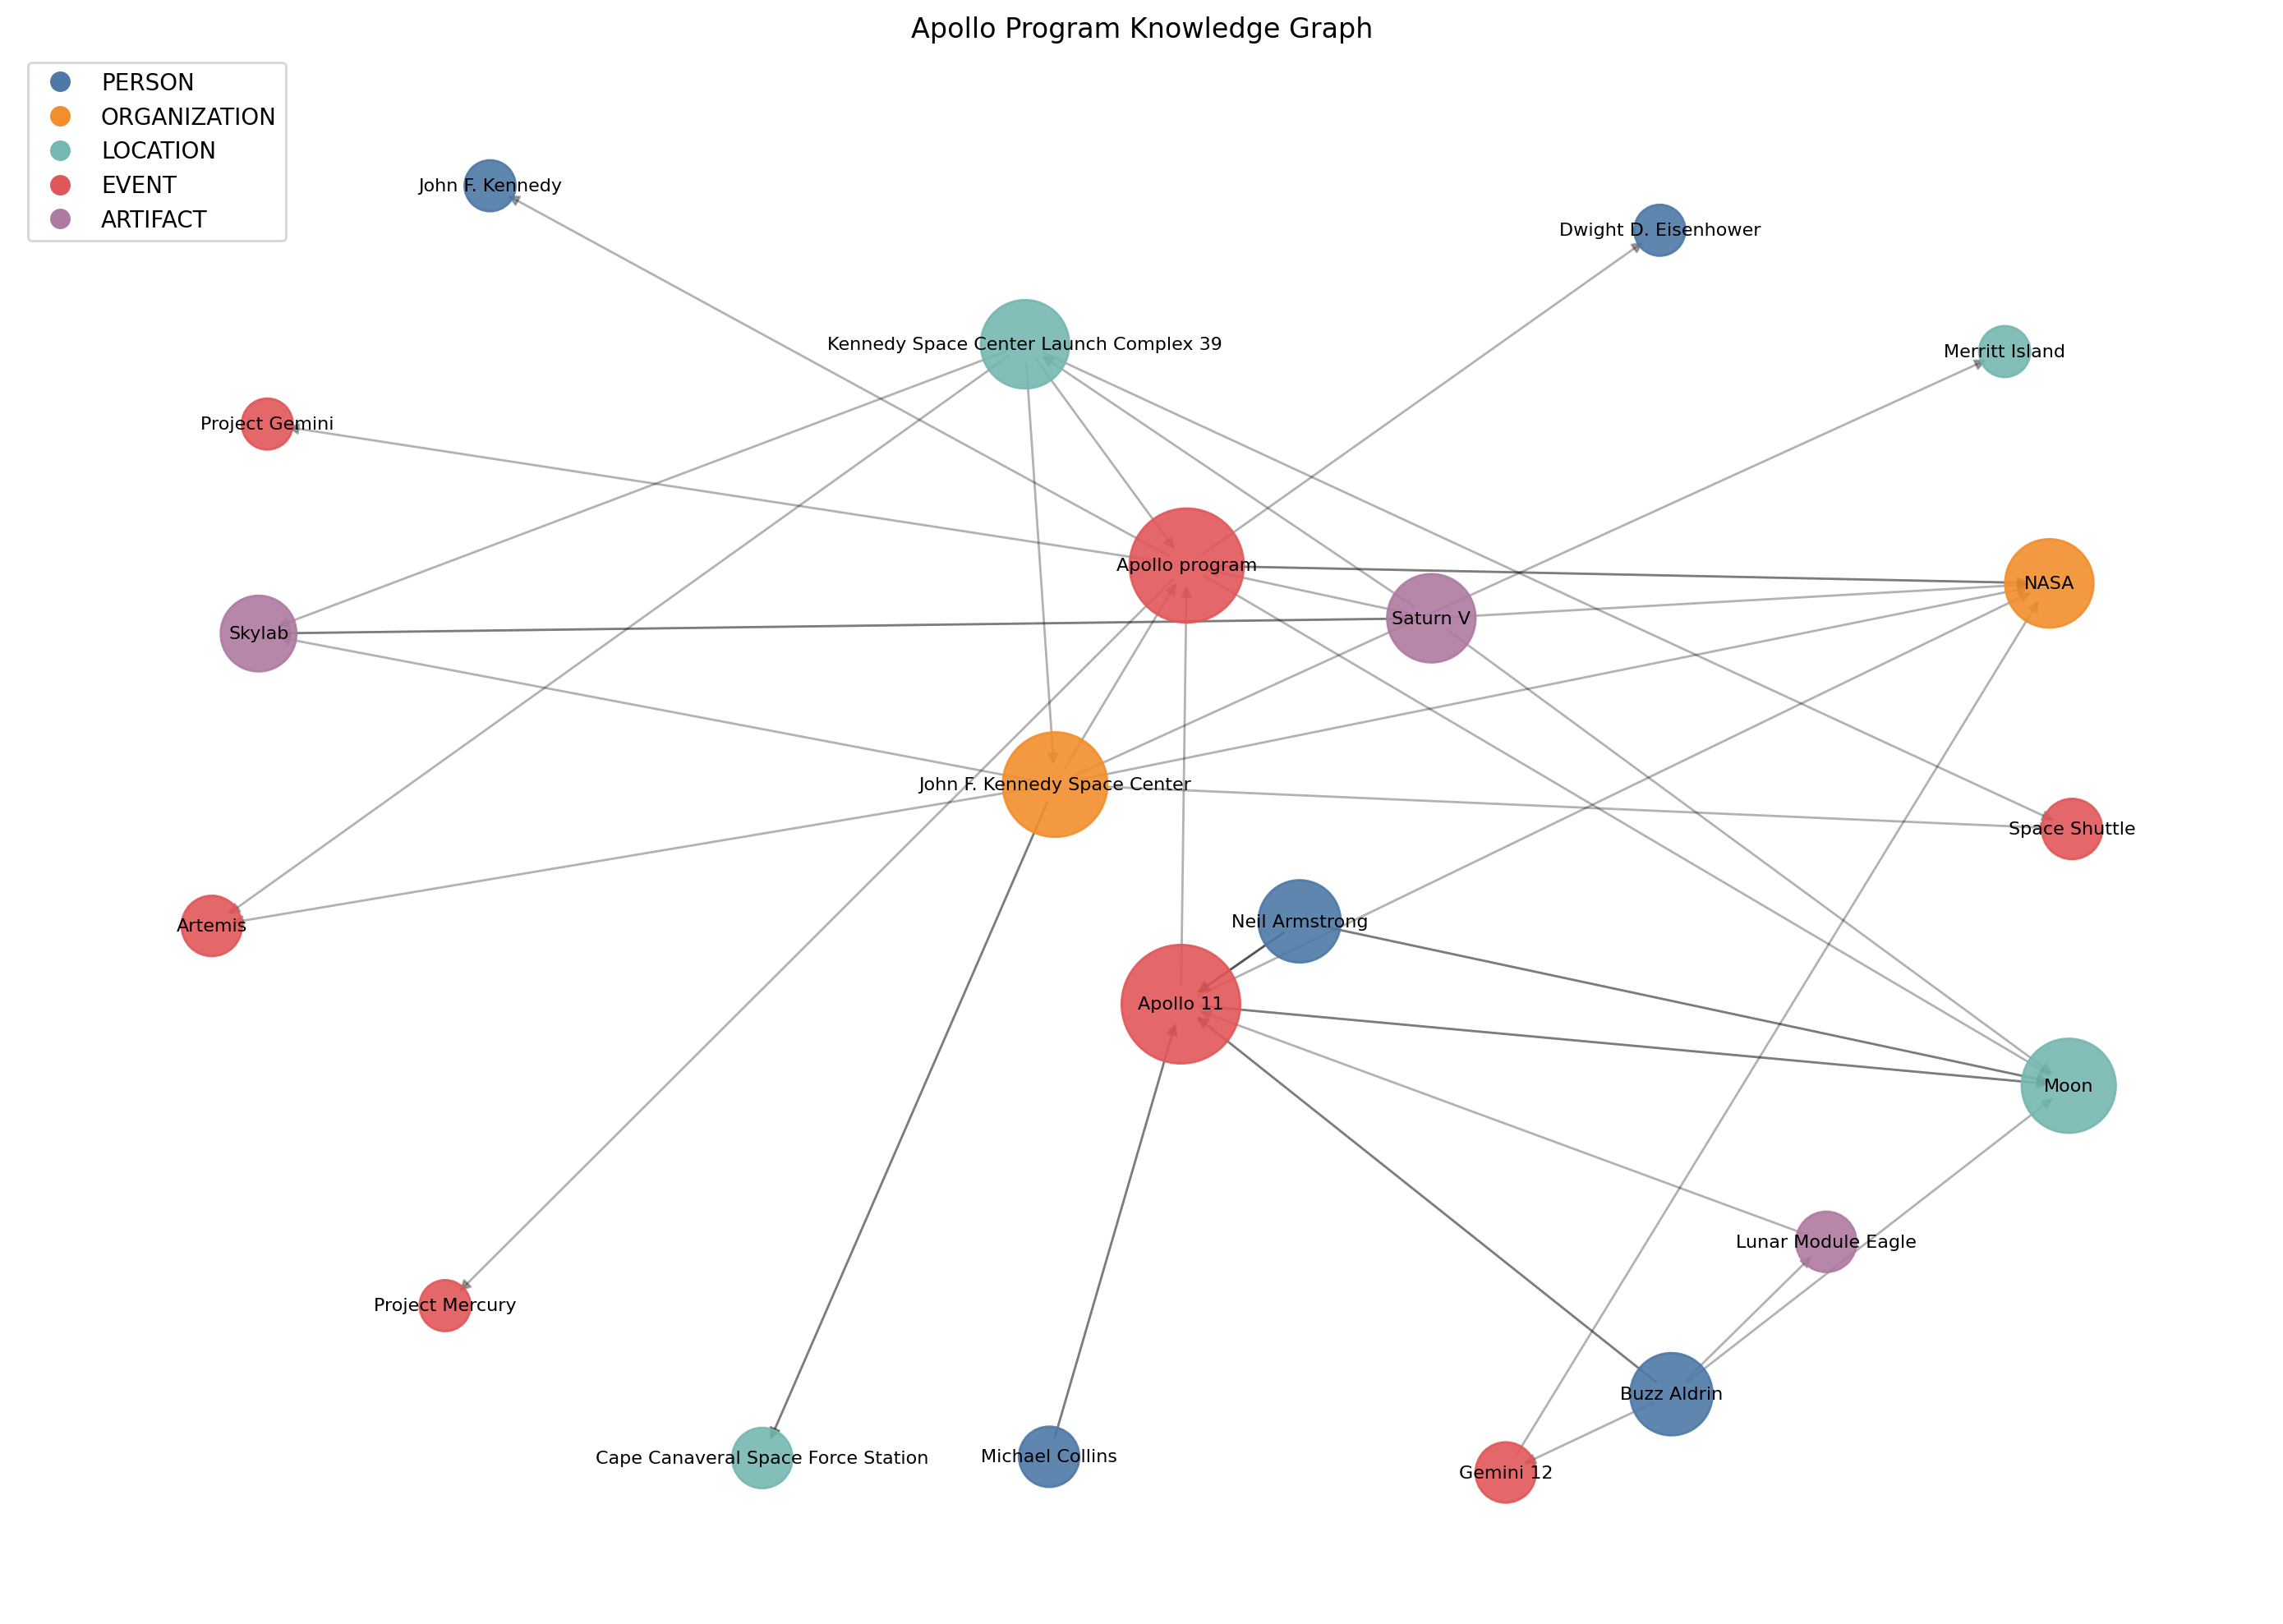

In [10]:
COLOR = {
    "PERSON": "#4e79a7",
    "ORGANIZATION": "#f28e2c",
    "LOCATION": "#76b7b2",
    "EVENT": "#e15759",
    "ARTIFACT": "#af7aa1",
}

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=1.5, seed=42)
node_colors = [COLOR[G.nodes[n]["type"]] for n in G.nodes]
node_sizes = [300 + 200 * G.degree(n) for n in G.nodes]

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, alpha=0.3, arrows=True, arrowsize=10)

handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=10, label=t)
    for t, c in COLOR.items()
    if any(G.nodes[n]["type"] == t for n in G.nodes)
]
plt.legend(handles=handles, loc="upper left")
plt.title("Apollo Program Knowledge Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

Node size scales with degree — the hubs are the entities that tie the corpus together. Color encodes type: if your graph is mostly one color, your corpus is narrow; a good mix means the extractor is finding the full cast of people, places, and things. A single connected component means entity resolution did its job — fragmented islands would indicate variants that should have merged but didn't.

## Entity summarization

Each node currently carries only the one-line description from whichever document mentioned it first. For the hub nodes — the ones that show up in many documents — we can do much better: pool every mention, add the graph neighborhood as context, and have Claude synthesize a proper profile.

This is the step that turns a graph of labels into a graph of knowledge. The summaries become the node content you surface in search results or feed to downstream QA.

In [11]:
class TimeRange(BaseModel):
    start: str  # YYYY or YYYY-MM, or "unknown"
    end: str  # YYYY or YYYY-MM, or "ongoing"


class EntityProfile(BaseModel):
    summary: str
    key_facts: list[str]
    time_range: TimeRange


SUMMARIZE_PROMPT = """Generate a knowledge-graph profile for this entity.

Entity: {name} ({etype})

Source excerpts mentioning this entity:
{excerpts}

Known relations in the graph:
{relations}

Write a 2-3 paragraph factual summary synthesized from the excerpts, resolving any contradictions by preferring the most specific claim. Include 3-5 atomic key facts, each traceable to the sources. For the time range, use YYYY or YYYY-MM format, or "unknown"/"ongoing" where appropriate. Do not invent facts not supported by the excerpts."""


def summarize_entity(name: str) -> EntityProfile:
    # Reads module-level G and documents built earlier in the notebook.
    docs_with_entity = G.nodes[name]["source_docs"]
    excerpts = "\n\n".join(
        f"[{d['title']}]\n{d['text']}" for d in documents if d["title"] in docs_with_entity
    )
    relations = (
        "\n".join(
            f"- {name} --{d['predicate']}--> {tgt}" for _, tgt, d in G.out_edges(name, data=True)
        )
        + "\n"
        + "\n".join(
            f"- {src} --{d['predicate']}--> {name}" for src, _, d in G.in_edges(name, data=True)
        )
    )

    response = client.messages.parse(
        model=SYNTHESIS_MODEL,
        max_tokens=4096,
        messages=[
            {
                "role": "user",
                "content": SUMMARIZE_PROMPT.format(
                    name=name, etype=G.nodes[name]["type"], excerpts=excerpts, relations=relations
                ),
            }
        ],
        output_format=EntityProfile,
    )
    return response.parsed_output

In [12]:
hub_nodes = [n for n, _ in sorted(G.degree(), key=lambda x: -x[1])[:3]]

for node in hub_nodes:
    profile = summarize_entity(node)
    G.nodes[node]["profile"] = profile.model_dump()
    print(f"═══ {node} ═══")
    print(profile.summary)
    print(f"\nTime range: {profile.time_range.start} – {profile.time_range.end}")
    print("Key facts:")
    for fact in profile.key_facts:
        print(f"  • {fact}")
    print()

═══ Apollo 11 ═══
Apollo 11 was the American spaceflight that first landed humans on the Moon. It was the fifth crewed mission of NASA's Apollo program, conducted by NASA, and took place in 1969. The Lunar Module Eagle was part of the mission. The crew was Commander Neil Armstrong, Command Module Pilot Michael Collins, and Lunar Module Pilot Edwin Buzz Aldrin. All three were on their second and final spaceflight. Armstrong became the first person to walk on the Moon, and Aldrin was the second. Aldrin had earlier made three spacewalks on NASA's 1966 Gemini 12 mission. Armstrong died in 2012 and Collins in 2021, which leaves Aldrin as the last surviving Apollo 11 crew member and the oldest living astronaut.

Time range: 1969 – 1969
Key facts:
  • Apollo 11 was the first spaceflight to land humans on the Moon.
  • Apollo 11 was the fifth crewed mission of NASA's Apollo program.
  • The crew was Neil Armstrong (Commander), Michael Collins (Command Module Pilot) and Buzz Aldrin (Lunar Modul

## Querying the graph

The payoff of building a knowledge graph is multi-hop reasoning: answering questions that require chaining facts that never co-occur in a single document. "Which locations are connected to people who flew on Apollo 11?" needs the extractor to have found person→mission edges in one document and person→location edges in another, then the resolver to have unified the person nodes so those edges actually meet.

We serialize a relevant subgraph as triples and let Claude reason over it. For comparison, we first ask the same question with no graph context.

In [13]:
def serialize_subgraph(center: str, hops: int = 2) -> str:
    nodes = {center}
    frontier = {center}
    for _ in range(hops):
        nxt = set()
        for n in frontier:
            nxt |= set(G.successors(n)) | set(G.predecessors(n))
        frontier = nxt - nodes
        nodes |= frontier
    sub = G.subgraph(nodes)
    lines = [f"({s}) --[{d['predicate']}]--> ({t})" for s, t, d in sub.edges(data=True)]
    return "\n".join(sorted(set(lines)))


def ask(question: str, graph_context: str | None = None) -> str:
    if graph_context is not None:
        prompt = f"""Answer using only the knowledge graph below. Cite the specific edges that support your answer.

<graph>
{graph_context}
</graph>

Question: {question}"""
    else:
        prompt = question
    response = client.messages.create(
        model=SYNTHESIS_MODEL,
        max_tokens=4096,  # leaves room for adaptive thinking before the answer
        messages=[{"role": "user", "content": prompt}],
    )
    text_block = next((b for b in response.content if b.type == "text"), None)
    if text_block is None:
        raise ValueError(f"No text block in response (stop_reason={response.stop_reason})")
    return text_block.text

In [14]:
center = next((n for n in G.nodes if "Apollo" in n), hub_nodes[0])
print(f"Querying 2-hop neighborhood of: {center}\n")
subgraph = serialize_subgraph(center, hops=2)

question = "Which locations are connected to people who were part of Apollo 11, and how?"

print("WITHOUT graph context:")
print(ask(question))
print("\n" + "─" * 60 + "\n")
print("WITH graph context:")
print(ask(question, subgraph))

Querying 2-hop neighborhood of: Apollo program

WITHOUT graph context:
# Locations linked to Apollo 11 people

I've grouped these by connection type, focusing mainly on the three crew members, with a few others at the end.

## Birthplaces and hometowns
- **Wapakoneta, Ohio**: Neil Armstrong's hometown, now home to the Armstrong Air & Space Museum.
- **Glen Ridge and Montclair, New Jersey**: Buzz Aldrin was born in Glen Ridge and attended Montclair High School.
- **Rome, Italy**: Michael Collins was born here, where his father was a U.S. Army officer.

## Education and military training
- **Purdue University (Indiana)**: Armstrong studied aeronautical engineering here.
- **U.S. Military Academy, West Point (New York)**: Both Aldrin and Collins graduated from here.
- **MIT (Massachusetts)**: Aldrin earned his doctorate in astronautics, with a thesis on orbital rendezvous.
- **Korea**: Armstrong flew Navy combat missions, and Aldrin flew Air Force combat missions.

## Careers before and a

The ungrounded answer draws on Claude's pretraining and may be correct — Apollo 11 is famous. But the grounded answer is **traceable**: every claim cites an edge we extracted from a specific document. On a private corpus where Claude has no prior knowledge, only the grounded answer works at all.

## Evaluation

Knowledge graph quality is measured with precision and recall against a gold set. We ship a small hand-labeled set in `data/sample_triples.json` covering two of the articles, plus `data/alias_map.json` which normalizes surface-form variants to the gold names so that "the Moon" and "Moon" count as the same hit.

The check below scores two things side by side: raw extractor output, and the same entities after passing through `alias_to_canonical` from the resolution step. When the resolver picks a canonical form the alias map knows about (or that matches gold verbatim), resolved recall climbs. When it picks a verbose form the alias map doesn't cover — say "Neil Alden Armstrong" — resolved recall can *drop*, because a name that matched gold before resolution no longer does after. That's not a resolver bug; it's a scoring artifact. The fix is to extend `alias_map.json` whenever you see a canonical form the scorer doesn't recognize.

This cell scores entities only. The standalone script also scores relations, matching on (source, target) pairs with predicate wording ignored — so its relation recall is an upper bound. Run it from the repo root:

```bash
uv run python capabilities/knowledge_graph/evaluation/eval_extraction.py
```

In [15]:
# Expects the kernel launched from this notebook's directory
# (capabilities/knowledge_graph/). Falls back to repo root.
data_dir = Path("data")
if not data_dir.exists():
    data_dir = Path("capabilities/knowledge_graph/data")

with open(data_dir / "sample_triples.json", encoding="utf-8") as f:
    gold = json.load(f)
with open(data_dir / "alias_map.json", encoding="utf-8") as f:
    ALIASES = json.load(f)


def norm(name: str) -> str:
    lower = name.lower().strip()
    return ALIASES.get(lower, lower)


def prf(predicted: set, gold: set) -> tuple[float, float, float]:
    tp = len(predicted & gold)
    p = tp / len(predicted) if predicted else 0.0
    r = tp / len(gold) if gold else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    return p, r, f1


print("Raw extraction vs resolved-graph recall against gold:\n")
for doc_title, labels in gold.items():
    gold_names = {norm(e["name"]) for e in labels["entities"]}

    raw = {norm(e["name"]) for e in raw_entities if e["source_doc"] == doc_title}
    rp, rr, rf = prf(raw, gold_names)

    resolved = {
        norm(alias_to_canonical.get(e["name"], e["name"]))
        for e in raw_entities
        if e["source_doc"] == doc_title
    }
    _, resolved_r, _ = prf(resolved, gold_names)

    print(f"{doc_title:<20}  raw F1={rf:.2f} (P={rp:.2f} R={rr:.2f})  resolved R={resolved_r:.2f}")
    missed = gold_names - resolved
    if missed:
        print(f"  still missed after resolution: {', '.join(sorted(missed))}")

Raw extraction vs resolved-graph recall against gold:

Apollo 11             raw F1=0.78 (P=1.00 R=0.64)  resolved R=0.64
  still missed after resolution: columbia, kennedy space center, lunar module eagle, saturn v
Neil Armstrong        raw F1=0.55 (P=1.00 R=0.38)  resolved R=0.38
  still missed after resolution: gemini 8, korean war, nasa, purdue university, united states navy


## Scaling up

This notebook processed six documents in memory. Production knowledge graphs are built from thousands. A few notes on scaling:

**Extraction cost.** Haiku is cheap enough to run on large corpora, but [prompt caching](https://docs.claude.com/en/docs/build-with-claude/prompt-caching) cuts costs further when your extraction schema and instructions stay fixed — cache the system prompt and schema, pay full price only for the document text. The [Message Batches API](https://docs.claude.com/en/docs/build-with-claude/batch-processing) gives 50% off for jobs that can wait up to 24 hours.

**Entity resolution at scale.** Feeding ten thousand PERSON entities to Claude in one prompt doesn't work. Block first: group candidates by cheap signals (same last name, overlapping tokens, embedding similarity) so Claude only arbitrates within small blocks. The resolution prompt above works unchanged on blocks of 50–100.

**Incremental updates.** When a new document arrives, extract its entities, resolve them against the existing canonical set (not against each other), and add only the new edges. Re-summarize an entity only when its source-document set changes materially.

**Storage.** NetworkX is fine to a few hundred thousand edges. Beyond that, the schema maps directly onto a property graph (Neo4j, Neptune) or three Postgres tables: `entities(id, name, type, summary)`, `relations(source_id, target_id, predicate)`, `aliases(entity_id, alias)`. The extraction and resolution code doesn't change — only the persistence layer does.

## Summary

You've built a complete knowledge graph pipeline with nothing but prompts:

- **Extraction** — a single structured-output call per document replaced what used to be a trained NER model plus a trained relation classifier. The Pydantic schema is the only "training" required.
- **Resolution** — Claude clustered surface forms using the extraction descriptions as context, catching cases like "Edwin Aldrin" → "Buzz Aldrin" that string similarity misses entirely.
- **Summarization** — hub nodes got rich profiles synthesized across every document that mentioned them, with structured time ranges and traceable key facts.
- **Querying** — serialized subgraphs let Claude answer multi-hop questions with edge-level citations, grounding answers in the graph you built rather than pretraining.

The evaluation harness in `evaluation/` gives you a feedback loop: change the extraction prompt, rerun the scorer, watch the F1 move. That loop is what turns a demo into a production system.

## Related cookbooks

- [Extracting structured JSON](../../tool_use/extracting_structured_json.ipynb) — the tool-use approach to the same extraction pattern, useful when you're already in an agentic tool-calling flow
- [Retrieval augmented generation](../retrieval_augmented_generation/guide.ipynb) — the complementary approach when you need document retrieval rather than fact traversal
- [Contextual embeddings](../contextual-embeddings/guide.ipynb) — enriching chunks before embedding, the same "add context before indexing" idea applied to vector search